# 01 — Random Forest regression (Ruo Wu, Lab 3)

**Question:** how well does an ensemble of decision trees predict hourly
rentals (`cnt`) from the 23 shared features?

**Why a random forest:** it averages many trees grown on bootstrap samples,
so it captures interactions (hour × working day, temperature × weather)
without feature scaling, and its feature importance is easy to explain.
Weaknesses: large file, no extrapolation beyond the training range.

**Protocol (same for all four notebooks):** fit on train, choose settings on
validation, evaluate test once. Metric: MAE (primary), RMSE, R².

| Section | What it shows |
|---|---|
| 1 | Load the shared data |
| 2 | Baselines (mean, ridge) |
| 3 | 36-setting grid search on validation |
| 4 | Selected forest |
| 5 | Validation / test results and diagnostics |
| 6 | Cost and saved evidence |
| 7 | Conclusion |

## 1. Setup
`bike_common` holds the shared split, features, metrics and plots.

**Data pipeline at a glance** (what `bike_common` does before any model sees the data):

1. reads `hour.csv` and rebuilds a complete hourly calendar — the 165 missing hours are added back;
2. forward-fills weather and past demand from earlier hours only; `cnt` stays empty at missing hours, so it is never a target;
3. builds the 23 shared features: one-hot season and weather, sin/cos month, hour and weekday, holiday and working-day flags, four weather values, and `lag1`, `lag24`, `lag168`, `roll24`, `roll168`;
4. assigns the frozen split (train → 2012-05-25, validation → 2012-09-12, test → 2012-12-31) and drops the two-week warm-up;
5. fits the scaler on training rows only.

`prepare_tabular()` returns one row per hour; `prepare_sequences(window)` returns the same rows as sliding windows.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for p in [Path.cwd(), *Path.cwd().parents]:            # locate the shared module
    hits = [q for q in (p, p / "src", p / "code" / "src") if (q / "bike_common.py").exists()]
    if hits:
        sys.path.insert(0, str(hits[0]))
        break
import bike_common as bc

bc.setup_plot_style()
SEED = bc.SEED
d = bc.prepare_tabular()
print(f"Rows: train {len(d['y_train']):,} | validation {len(d['y_validation']):,} "
      f"| test {len(d['y_test']):,} | features {len(d['feature_names'])}")

Rows: train 11,816 | validation 2,640 | test 2,600 | features 23


## 2. Baselines
A useful model must clearly beat the training mean and a linear ridge model.

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge

baselines = {}
for name, model in [("mean", DummyRegressor()), ("ridge", Ridge(alpha=1.0, random_state=SEED))]:
    t0 = time.perf_counter()
    model.fit(d["X_train"], d["y_train"])
    baselines[name] = {
        "validation": bc.regression_metrics(d["y_validation"], model.predict(d["X_validation"])),
        "test": bc.regression_metrics(d["y_test"], model.predict(d["X_test"])),
        "fit_seconds": time.perf_counter() - t0,
    }
pd.DataFrame({n: {f"{s} {m}": v[s][m] for s in ("validation", "test") for m in ("MAE", "RMSE", "R2")}
              for n, v in baselines.items()}).T.round(3)

,validation MAE,validation RMSE,validation R2,test MAE,test RMSE,test R2
mean,193.622,253.250,-0.283,168.087,226.141,-0.114
ridge,53.848,79.318,0.874,51.410,77.676,0.869


## 3. Grid search (validation only)
2 tree counts × 3 depths × 3 leaf sizes × 2 feature fractions = 36 forests.

**Selection rule:** keep every setting within 1.0 rental/hour of the best
validation MAE, then prefer finite depth → fewer trees → larger leaves.
This avoids the ~178 MB unlimited-depth forest for a negligible MAE gain.

In [3]:
from itertools import product
from sklearn.ensemble import RandomForestRegressor

records, models = [], {}
for n_est, depth, leaf, feat in product([200, 400], [12, 20, None], [1, 2, 4], ["sqrt", 0.6]):
    tag = f"n{n_est}_d{depth}_l{leaf}_m{feat}"
    t0 = time.perf_counter()
    model = RandomForestRegressor(n_estimators=n_est, max_depth=depth, min_samples_leaf=leaf,
                                  max_features=feat, random_state=SEED, n_jobs=-1)
    model.fit(d["X_train"], d["y_train"])
    m = bc.regression_metrics(d["y_validation"], model.predict(d["X_validation"]))
    records.append({"tag": tag, "n_estimators": n_est,
                    "max_depth": depth if depth is not None else "None",
                    "min_samples_leaf": leaf, "max_features": feat, "val_MAE": m["MAE"],
                    "val_RMSE": m["RMSE"], "val_R2": m["R2"],
                    "fit_seconds": time.perf_counter() - t0})
    models[tag] = model

search = pd.DataFrame(records).sort_values("val_MAE").reset_index(drop=True)
search.head(10).round(3)

,tag,n_estimators,max_depth,min_samples_leaf,max_features,val_MAE,val_RMSE,val_R2,fit_seconds
0,n400_dNone_l2_m0.6,400,None,2,0.6,39.375,61.887,0.923,5.490
1,n400_d20_l2_m0.6,400,20,2,0.6,39.513,61.814,0.924,7.454
2,n400_dNone_l1_m0.6,400,None,1,0.6,39.804,62.282,0.922,7.477
3,n200_d20_l2_m0.6,200,20,2,0.6,39.845,62.402,0.922,2.721
4,n200_dNone_l2_m0.6,200,None,2,0.6,39.869,62.796,0.921,2.783
5,n400_d12_l2_m0.6,400,12,2,0.6,39.877,62.385,0.922,4.114
6,n400_d20_l4_m0.6,400,20,4,0.6,39.912,62.794,0.921,5.633
7,n200_dNone_l1_m0.6,200,None,1,0.6,39.958,62.548,0.922,3.237
8,n200_d12_l2_m0.6,200,12,2,0.6,40.075,62.555,0.922,2.035
9,n400_dNone_l4_m0.6,400,None,4,0.6,40.218,63.264,0.920,5.146


## 4. Selected forest

In [4]:
TOLERANCE = 1.0
best_mae = float(search["val_MAE"].min())
close = search[search["val_MAE"] <= best_mae + TOLERANCE].assign(
    depth_pref=lambda f: (f["max_depth"] == "None").astype(int),
    n_pref=lambda f: f["n_estimators"].astype(int),
    leaf_pref=lambda f: -f["min_samples_leaf"].astype(int))
best_row = close.sort_values(["depth_pref", "n_pref", "leaf_pref", "val_MAE"]).iloc[0]
best_tag = best_row["tag"]
best_model = models[best_tag]
print(f"Best validation MAE in grid {best_mae:.2f}; {len(close)} settings within {TOLERANCE}")
print("Selected:", best_tag, "| validation MAE", round(best_row["val_MAE"], 2))

Best validation MAE in grid 39.38; 16 settings within 1.0
Selected: n200_d20_l4_m0.6 | validation MAE 40.23


## 5. Results
Validation chose the model; test is the one-off later-period check.
MAE ≈ 35 means a typical hour is off by about 35 rentals. R² is variance
explained, not accuracy.

In [5]:
val_pred = best_model.predict(d["X_validation"])
test_pred = best_model.predict(d["X_test"])
ev = bc.evaluate(d["y_validation"], val_pred, d["y_test"], test_pred,
                 d["validation"], d["test"], d["train"])
bc.scenario_table(ev)

Validation: MAE 40.23 | RMSE 63.18 | R2 0.9202
Test:       MAE 35.56 | RMSE 58.54 | R2 0.9254


,validation n,validation MAE,test n,test MAE
peak_hours,660,70.79,653,67.43
off_peak_hours,1980,30.04,1947,24.87
weekday,1800,40.10,1737,36.99
weekend_or_holiday,840,40.51,863,32.68
high_demand,1381,56.67,1055,59.11
lower_demand,1259,22.19,1545,19.48


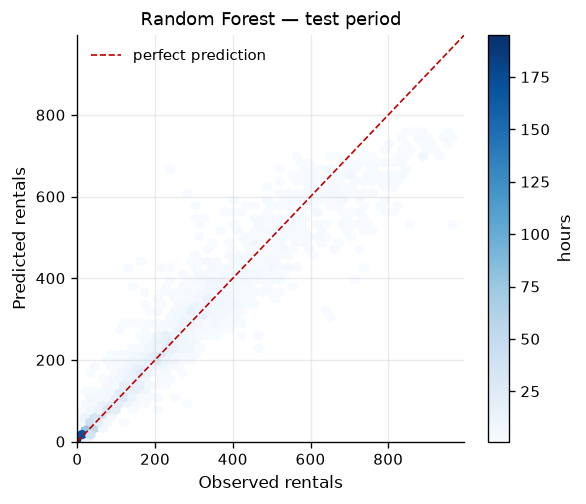

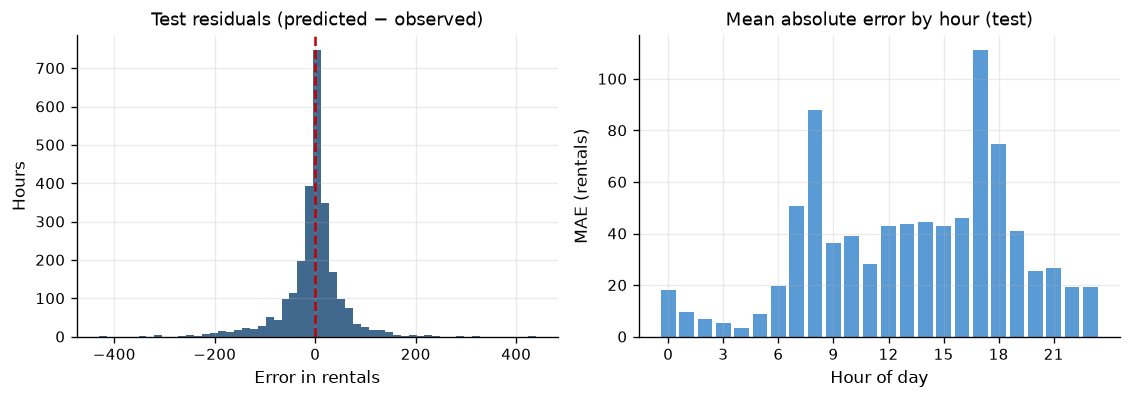

Residual mean -3.98 | standard deviation 58.40


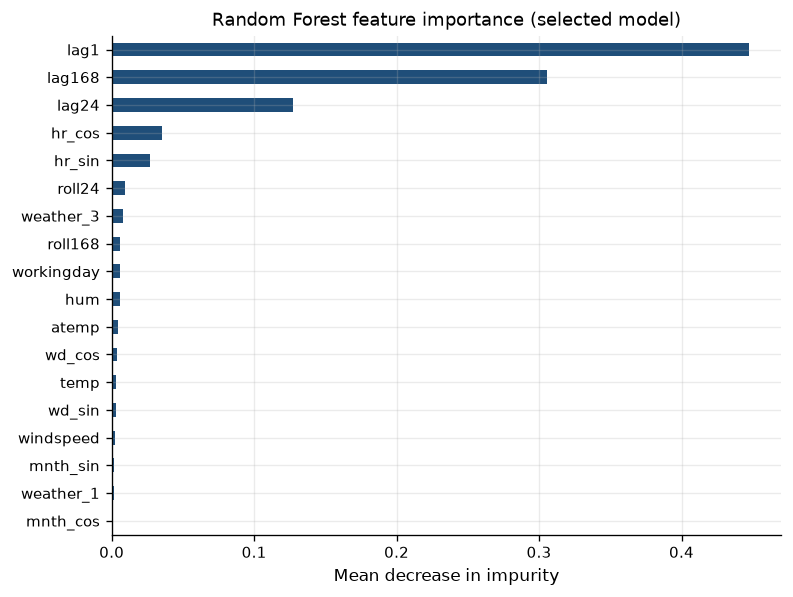

In [6]:
bc.plot_diagnostics(d["y_test"], test_pred, d["test"]["hr"], "Random Forest", "rf")

importance = pd.Series(best_model.feature_importances_, index=d["feature_names"]).sort_values()
fig, ax = plt.subplots(figsize=(7.2, 5.4))
importance.tail(18).plot.barh(ax=ax, color="#1f4e79")
ax.set(title="Random Forest feature importance (selected model)",
       xlabel="Mean decrease in impurity")
bc.save_figure(fig, "fig_rf_feature_importance.png")
plt.show()

The history features (`lag1`, `roll24`) dominate, then hour and temperature.
Largest test misses, with their calendar and weather context:

In [7]:
bc.worst_errors(d["test"], test_pred)

/home/peterhanhhh/IntroToAI/AI project/project/src/bike_common.py:718: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  return frame.loc[frame["error"].abs().sort_values(ascending=False).index[:n], cols].round(1)


,dteday,hr,weekday,workingday,weathersit,temp,hum,cnt,prediction,error
882,2012-10-19,18,5,1,1,0.6,0.8,233,671.8,438.8
305,2012-09-25,17,2,1,1,0.7,0.4,967,536.3,-430.7
1244,2012-11-05,8,1,1,2,0.3,0.5,648,311.0,-337.0
138,2012-09-18,18,2,1,2,0.6,0.9,281,608.5,327.5
449,2012-10-01,17,1,1,3,0.6,0.6,856,539.1,-316.9
632,2012-10-09,8,2,1,2,0.4,0.8,713,400.2,-312.8
1253,2012-11-05,17,1,1,1,0.3,0.5,638,327.0,-311.0
776,2012-10-15,8,1,1,2,0.6,0.6,737,428.7,-308.3
464,2012-10-02,8,2,1,3,0.6,0.9,134,423.3,289.3
593,2012-10-07,17,0,0,3,0.4,0.8,157,446.1,289.1


## 6. Cost and saved evidence
Model size and latency feed the final scorecard; notebook 05 reads the JSON
and CSV files written here instead of retraining.

In [8]:
import joblib

model_path = bc.MODELS_DIR / "random_forest.joblib"
scaler_path = bc.MODELS_DIR / "scaler.joblib"
joblib.dump(best_model, model_path)
d["scaler"].save(scaler_path)
latency = bc.measure_inference(best_model.predict, d["X_test"])
print(f"Model {bc.file_mb(model_path):.2f} MB | single row {latency['single_row_ms']:.2f} ms "
      f"| batch {latency['batch_seconds'] * 1000:.0f} ms for {latency['batch_rows']} rows")

bc.save_predictions(d["test"], test_pred, "pred_rf_test.csv")
bc.save_predictions(d["validation"], val_pred, "pred_rf_validation.csv")
bc.save_json({
    "method": "Random Forest", "owner": "Ruo Wu", "lab": "Lab 3",
    "selected_tag": best_tag,
    "selection_rule": {"primary": "validation MAE", "tolerance_MAE": TOLERANCE,
                       "tie_break": "finite depth, fewer trees, larger leaves, then MAE",
                       "best_val_MAE_in_grid": best_mae},
    "selected_params": {
        "n_estimators": int(best_row["n_estimators"]),
        "max_depth": None if best_row["max_depth"] == "None" else int(best_row["max_depth"]),
        "min_samples_leaf": int(best_row["min_samples_leaf"]),
        "max_features": best_row["max_features"], "random_state": SEED},
    **ev,
    "baselines": baselines,
    "search": search.to_dict(orient="records"),
    "feature_importance": importance.sort_values(ascending=False).round(6).to_dict(),
    "fit_seconds_selected": float(best_row["fit_seconds"]),
    "model_size_mb": bc.file_mb(model_path), "scaler_size_mb": bc.file_mb(scaler_path),
    "inference": latency, "train_rows": int(len(d["y_train"])), "features": d["feature_names"],
}, "rf_metrics.json")
print("Saved results/rf_metrics.json, prediction CSVs and models/random_forest.joblib")

Model 41.37 MB | single row 69.66 ms | batch 89 ms for 2600 rows
Saved results/rf_metrics.json, prediction CSVs and models/random_forest.joblib


## 7. Conclusion
* The forest beats both baselines clearly and is the strongest tabular model.
* Strengths: no scaling needed, readable feature importance.
* Costs: the largest file (≈41 MB) and the slowest single-row prediction.
* The final choice is made in notebook 05, not here.